# MV-MGB: Multi-View Meta-Gradient Boosting for Non-Coding RNA Classification
### *Interactive Inference & Diagnostic Triage Tutorial*
**Expert Systems with Applications (ESWA), Elsevier Q1**  
Authors: Rabah Lebsir and Abdelbasset Boukelia  
Corresponding Email: `rabah.lebsir@univ-guelma.dz` / `a.boukelia@crbt.dz`  
GitHub: https://github.com/BoukeliaAbdelbasset/MV-MGB | Zenodo: https://zenodo.org/records/23724491

---

## Overview
**MV-MGB** is an explainable, CPU-native decision support system that classifies non-coding RNA (ncRNA) transcripts into functional families with state-of-the-art accuracy (**95.65%**, 0.9564 weighted F1) in $\mathcal{O}(L)$ linear time. 

Instead of relying on multi-GPU foundation models or monolithic feature concatenation, MV-MGB simultaneously maps each RNA sequence across **four complementary biophysical and geometric feature spaces**:
1. **View 1: Sublinear TF-IDF Oligonucleotide Spectra (35,000D)** — capturing short motif sequences ($k \in [3, 8]$).
2. **View 2: Topological Natural Vector Moments (21D)** — capturing global nucleotide position distributions.
3. **View 3: Biophysical Structural Fingerprints (22D)** — capturing base-pairing rules, hairpins, and self-complementarity.
4. **View 4: Continuous Turner Thermodynamic Stacking B-Splines (60D)** — capturing nearest-neighbour stacking free energy profiles.

These representations feed specialized Tier-1 base estimators that generate out-of-fold probability simplices ($\Delta^{12}$), which are fused by a Tier-2 Histogram Gradient Boosted Decision Tree (HistGBDT) meta-learner without data leakage.

### What this Tutorial Covers:
- **Part 1:** Setting up the environment and loading the pre-trained model
- **Part 2:** Feature extraction and inspection across all 4 biophysical views
- **Part 3:** Single-transcript inference and confidence score prediction
- **Part 4:** Visualizing the multi-class probability simplex
- **Part 5:** Chow-type Bayesian 3-way diagnostic triage (Automated Accept vs. Expert Review vs. Out-of-Distribution Rejection)
- **Part 6:** Batch FASTA screening and exporting results

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
sys.path.insert(0, ".")

from src.pipeline import MVMGBClassifier
from src.canonicalization import canonicalize_rna
from src.data_loader import load_fasta_sequences

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['figure.dpi'] = 120

print("All required libraries imported successfully!")

All required libraries imported successfully!


## Part 1: Loading the Pre-Trained MV-MGB Model
We load the pre-trained model artifact trained on the verified 13-class Creux Dataset 1 benchmark. The model contains all four biophysical encoders, Tier-1 base pipelines, and the Tier-2 meta-learner.

In [2]:
model_path = "models/mvmgb_dataset1.joblib"

print(f"Loading pre-trained model from {model_path}...")
model = MVMGBClassifier.load(model_path)

print(f"Model successfully loaded!")
print(f"Registered Classes ({len(model.classes_)}):")
for i, c in enumerate(model.classes_, 1):
    print(f"  {i:2d}. {c}")

Loading pre-trained model from models/mvmgb_dataset1.joblib...


Model successfully loaded!
Registered Classes (13):
   1. 5S_rRNA
   2. 5_8S_rRNA
   3. CD-box
   4. HACA-box
   5. IRES
   6. Intron_gpI
   7. Intron_gpII
   8. leader
   9. miRNA
  10. riboswitch
  11. ribozyme
  12. scaRNA
  13. tRNA


## Part 2: Multi-View Feature Extraction & Biophysical Inspection
Let's inspect how MV-MGB transforms a raw ribonucleotide sequence into four rich mathematical representations in linear $\mathcal{O}(L)$ time.

We take a canonical transfer RNA (tRNA) sequence:

In [3]:
sample_trna = (
    "GGGCCCGUAGCUCAGUGGUAGAGCGCUCGCUUUGCAUGUGAGAGGUACCGGGAUCGAUACCCGGCGGGUCCA"
)

# 1. Canonicalization
canonical_seq = canonicalize_rna(sample_trna)
print(f"Input Sequence Length: {len(canonical_seq)} nt")
print(f"Canonicalized RNA:    {canonical_seq[:40]}... (T -> U standardized)")

# 2. Extract multi-view features
features = model.extract_features([sample_trna])

nv = features['view2_nv'][0]
bsf = features['view3_bsf'][0]
bsp = features['view4_bsp'][0]

print(f"\nFeature Dimensions:")
print(f"  - View 1 (TF-IDF String):              Raw sequence passed to pipeline")
print(f"  - View 2 (Natural Vectors):            {nv.shape[0]} dimensions")
print(f"  - View 3 (Structural Fingerprints):    {bsf.shape[0]} dimensions")
print(f"  - View 4 (Turner Stacking B-Splines):  {bsp.shape[0]} dimensions")

Input Sequence Length: 72 nt
Canonicalized RNA:    GGGCCCGUAGCUCAGUGGUAGAGCGCUCGCUUUGCAUGUG... (T -> U standardized)

Feature Dimensions:
  - View 1 (TF-IDF String):              Raw sequence passed to pipeline
  - View 2 (Natural Vectors):            21 dimensions
  - View 3 (Structural Fingerprints):    22 dimensions
  - View 4 (Turner Stacking B-Splines):  60 dimensions


### Visualizing View 4 & View 2 Representations
View 4 evaluates nearest-neighbour dinucleotide stacking free energies ($\Delta G^\circ$ at $37^\circ\text{C}$) and projected pairing propensities ($\Psi_{\text{pair}}$) across 12 cubic B-spline basis functions ($d=3$):

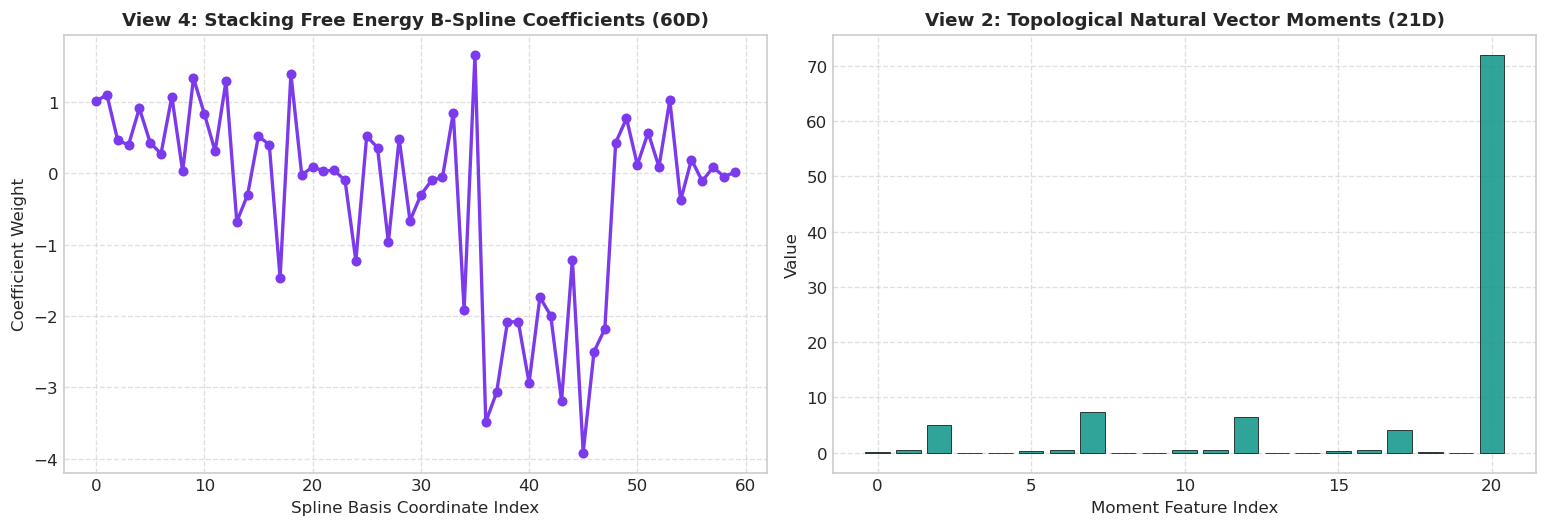

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot B-spline coefficients
axes[0].plot(bsp, marker="o", color="#7C3AED", linewidth=2, markersize=5)
axes[0].set_title("View 4: Stacking Free Energy B-Spline Coefficients (60D)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Spline Basis Coordinate Index", fontsize=10)
axes[0].set_ylabel("Coefficient Weight", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot View 2 Natural Vector moments
axes[1].bar(range(len(nv)), nv, color="#0D9488", alpha=0.85, edgecolor="black", linewidth=0.5)
axes[1].set_title("View 2: Topological Natural Vector Moments (21D)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Moment Feature Index", fontsize=10)
axes[1].set_ylabel("Value", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Part 3: Single-Transcript Inference & Classification
We can predict the functional family for any query RNA sequence using `.predict()` or `.predict_proba()`.

In [5]:
test_sequences = {
    "Transfer RNA (tRNA)": "GGGCCCGUAGCUCAGUGGUAGAGCGCUCGCUUUGCAUGUGAGAGGUACCGGGAUCGAUACCCGGCGGGUCCA",
    "MicroRNA (miRNA)": "UGAGGUAGUAGGUUGUAUAGUUUUAGGGUCACACCCACCACUGGGAGAUAACUAUACAAUCUACUGUCUUUC",
    "5S Ribosomal RNA (5S_rRNA)": "GCCUGGCGGCCGUAGCGCGGUGGUCCCACCUGACCCCAUGCCGAACUCAGAAGUGAAACGCCGUAGCGCCGAUGGUAGUGUGGGUCUCCCCAUGCGAGAGUAGGGAACUGCCAGGCA"
}

print(f"{'RNA Description':<30} {'Predicted Class':<18} {'Confidence':<12}")
print("-" * 62)

for desc, seq in test_sequences.items():
    pred_class = model.predict([seq])[0]
    prob = np.max(model.predict_proba([seq]))
    print(f"{desc:<30} {pred_class:<18} {prob*100:6.2f}%")

RNA Description                Predicted Class    Confidence  
--------------------------------------------------------------


Transfer RNA (tRNA)            tRNA               100.00%


MicroRNA (miRNA)               miRNA               88.26%


5S Ribosomal RNA (5S_rRNA)     5S_rRNA             99.97%


## Part 4: Visualizing the 13-Class Probability Simplex
Tier-2 Stacking produces an unbiased posterior distribution over the 13-simplex ($\Delta^{12}$). Let's plot the predicted probability distribution for the tRNA query sequence:

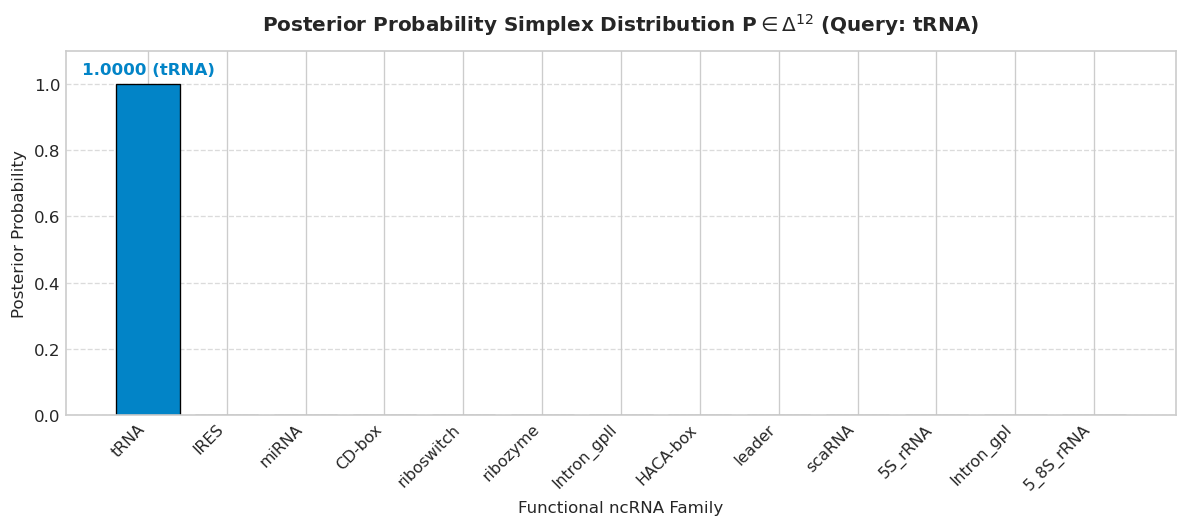

In [6]:
probs = model.predict_proba([sample_trna])[0]
df_probs = pd.DataFrame({
    "Class": model.classes_,
    "Probability": probs
}).sort_values("Probability", ascending=False)

plt.figure(figsize=(10, 4.5))
palette = ["#0284C7" if p == probs.max() else "#CBD5E1" for p in df_probs["Probability"]]
bars = plt.bar(df_probs["Class"], df_probs["Probability"], color=palette, edgecolor="black", linewidth=0.8)

plt.title("Posterior Probability Simplex Distribution $\\mathbf{P} \\in \\Delta^{12}$ (Query: tRNA)", fontsize=12, fontweight="bold", pad=12)
plt.ylabel("Posterior Probability", fontsize=10)
plt.xlabel("Functional ncRNA Family", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.ylim(0, 1.10)

max_p = df_probs["Probability"].iloc[0]
max_c = df_probs["Class"].iloc[0]
plt.text(0, max_p + 0.03, f"{max_p:.4f} ({max_c})", ha="center", fontweight="bold", color="#0284C7")

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## Part 5: Chow-Type Bayesian 3-Way Diagnostic Triage
In clinical diagnostics and high-throughput transcriptomics, unflagged false-positive errors carry high downstream wet-lab validation costs.

MV-MGB incorporates a formal **Chow-type Bayesian 3-way triage rule** with two tunable decision boundaries:
- **ACCEPT** ($p_{\max} \ge \tau_{\text{review}} = 0.85$): Automated high-confidence acceptance.
- **HUMAN_REVIEW** ($\tau_{\text{reject}} \le p_{\max} < \tau_{\text{review}}$): Low-confidence or ambiguous prediction routed to expert laboratory inspection.
- **REJECT_NOVEL** ($p_{\max} < \tau_{\text{reject}} = 0.50$): Candidate novel, uncharacterized family, or out-of-distribution sequence.

In [7]:
# 1. A confident canonical sequence
seq_known = "GGGCCCGUAGCUCAGUGGUAGAGCGCUCGCUUUGCAUGUGAGAGGUACCGGGAUCGAUACCCGGCGGGUCCA"

# 2. A synthetic sequence with randomized base order (OOD decoy)
np.random.seed(42)
seq_scrambled = "".join(np.random.choice(list("ACGU"), size=90))

triage_known = model.predict_triage([seq_known])[0]
triage_ood = model.predict_triage([seq_scrambled])[0]

print("1. Canonical tRNA Query:")
print(f"   Predicted:   {triage_known.predicted_class}")
print(f"   Confidence:  {triage_known.confidence:.4f}")
print(f"   Decision:    [{triage_known.action}] (Direct Automated Call)\n")

print("2. Synthetic Scrambled Decoy:")
print(f"   Predicted:   {triage_ood.predicted_class}")
print(f"   Confidence:  {triage_ood.confidence:.4f}")
print(f"   Decision:    [{triage_ood.action}]")

1. Canonical tRNA Query:
   Predicted:   tRNA
   Confidence:  1.0000
   Decision:    [ACCEPT] (Direct Automated Call)

2. Synthetic Scrambled Decoy:
   Predicted:   miRNA
   Confidence:  0.7651
   Decision:    [HUMAN_REVIEW]


## Part 6: High-Throughput Batch FASTA Screening
MV-MGB can process multi-thousand transcript FASTA files in seconds on standard CPU hardware. Let's screen the bundled demo FASTA file:

In [8]:
demo_fasta_path = "datasets/demo/demo_transcripts.fasta"
seq_ids, seqs, true_labels = load_fasta_sequences(demo_fasta_path)

print(f"Screening {len(seqs)} sequences from {demo_fasta_path}...")
df_batch = model.predict_dataframe(
    sequences=seqs,
    seq_ids=seq_ids,
    tau_review=0.85,
    tau_reject=0.50
)

# Display summary table
df_batch[["Sequence_ID", "Length", "Predicted_Class", "Confidence", "Triage_Action"]].head(14)

Screening 14 sequences from datasets/demo/demo_transcripts.fasta...


,Sequence_ID,Length,Predicted_Class,Confidence,Triage_Action
0,RF00001_AGFK01083378_1_200-82,119,5S_rRNA,0.999989,ACCEPT
1,RF00002_GQ402852_1_260-414,155,5_8S_rRNA,0.999997,ACCEPT
2,RF00012_BACK01012917_1_274-494,221,CD-box,0.999986,ACCEPT
3,RF00045_AAUQ01037944_1_452-670,219,HACA-box,0.999353,ACCEPT
4,RF00061_EF174006_1_13-271,259,IRES,0.999944,ACCEPT
5,RF00028_AJ308660_1_10-318,309,Intron_gpI,0.999996,ACCEPT
6,RF00029_U41288_1_27369-27451,83,Intron_gpII,0.999991,ACCEPT
7,RF00114_CP001790_1_860307-860424,118,leader,0.999996,ACCEPT
8,RF00051_BAAF04006740_1_10494-10412,83,miRNA,0.999997,ACCEPT
9,RF00050_AEPS01000012_1_4067-3920,148,riboswitch,0.999923,ACCEPT


In [9]:
summary = df_batch["Triage_Action"].value_counts()
print("Triage Summary:")
for action, count in summary.items():
    print(f"  {action:<14}: {count:2d} sequences ({count/len(df_batch)*100:5.1f}%)")

Triage Summary:
  ACCEPT        : 14 sequences (100.0%)


---
## Citation
If you use MV-MGB in your research, please cite our manuscript:

```bibtex
@article{lebsir2026mvmgb,
  title={An Explainable Multi-View Expert Decision Support System for Alignment-Free Non-Coding RNA Classification Using Biophysical and Geometric Feature Spaces},
  author={Lebsir, Rabah and Boukelia, Abdelbasset},
  journal={Expert Systems with Applications},
  year={2026},
  publisher={Elsevier}
}
```